In [3]:
 pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


# Wine Quality Prediction Using Random Forest Regression

## Project Overview

The objective of this project is to develop a Machine Learning
model that predicts wine quality using physicochemical properties.

### Technologies Used
- Python
- Jupyter Notebook
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Joblib

### Project Workflow
1. Load the UCI Wine Quality Dataset.
2. Perform data cleaning.
3. Perform feature scaling.
4. Train a Random Forest Regression model.
5. Evaluate the model using RMSE.
6. Extract and visualize feature importance.
7. Save the trained model for future predictions.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib
import json

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Set random seed for reproducibility
RANDOM_STATE = 42

# Configure visualization style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the UCI Red Wine Quality Dataset

DATA_URL = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/"
    "wine-quality/winequality-red.csv"
)

df = pd.read_csv(DATA_URL, sep=";")

# Display the first five records
print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
# Display dataset dimensions

print("Dataset Shape:", df.shape)

# Display column names
print("\nDataset Columns:")

print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")

df.info()

# Display statistical summary
print("\nStatistical Summary:")

display(df.describe())

Dataset Shape: (1599, 12)

Dataset Columns:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [4]:
# Create a copy of the original dataset

data = df.copy()

# Remove duplicate records

data.drop_duplicates(inplace=True)

# Convert all columns into numeric format

for column in data.columns:
    data[column] = pd.to_numeric(
        data[column],
        errors="coerce"
    )

# Replace infinite values with missing values

data.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)

# Remove records with missing target values

data.dropna(
    subset=["quality"],
    inplace=True
)

# Separate features and target

X = data.drop("quality", axis=1)

y = data["quality"]

# Display cleaning results

print("Data Cleaning Completed!")

print("Cleaned Dataset Shape:", data.shape)

print("\nMissing Values:")

display(data.isnull().sum())

print("\nDuplicate Records:", data.duplicated().sum())

Data Cleaning Completed!
Cleaned Dataset Shape: (1359, 12)

Missing Values:


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


Duplicate Records: 0


In [5]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset sizes

print("Training and Testing Split Completed!")

print("Training Features:", X_train.shape)

print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)

print("Testing Target:", y_test.shape)

Training and Testing Split Completed!
Training Features: (1087, 11)
Testing Features: (272, 11)
Training Target: (1087,)
Testing Target: (272,)


In [6]:
# Create preprocessing pipeline

preprocessing_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),

        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Fit preprocessing only on training data

X_train_scaled = preprocessing_pipeline.fit_transform(
    X_train
)

# Transform testing data using the same preprocessing

X_test_scaled = preprocessing_pipeline.transform(
    X_test
)

print("Feature Scaling Completed Successfully!")

print("Scaled Training Data Shape:", X_train_scaled.shape)

print("Scaled Testing Data Shape:", X_test_scaled.shape)

Feature Scaling Completed Successfully!
Scaled Training Data Shape: (1087, 11)
Scaled Testing Data Shape: (272, 11)


In [7]:
# Create Random Forest Regression model

random_forest_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=1.0,
    random_state=42,
    n_jobs=-1
)

# Train the model

random_forest_model.fit(
    X_train_scaled,
    y_train
)

print("Random Forest Regression Model Trained Successfully!")

Random Forest Regression Model Trained Successfully!


In [8]:
# Predict wine quality using testing data

y_pred = random_forest_model.predict(
    X_test_scaled
)

# Display actual and predicted values

results = pd.DataFrame({
    "Actual Quality": y_test.values,
    "Predicted Quality": y_pred
})

print("Prediction Completed Successfully!")

display(results.head(10))

Prediction Completed Successfully!


,Actual Quality,Predicted Quality
0,5,4.996667
1,6,5.996667
2,7,6.373333
3,5,5.543333
4,4,5.426667
5,7,6.796667
6,5,5.590000
7,5,5.116667
8,6,5.856667
9,5,5.556667


In [9]:
# Calculate Root Mean Squared Error

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

# Calculate Mean Absolute Error

mae = mean_absolute_error(
    y_test,
    y_pred
)

# Calculate R-squared score

r2 = r2_score(
    y_test,
    y_pred
)

# Display evaluation results

print("MODEL EVALUATION RESULTS")

print("--------------------------")

print(f"RMSE: {rmse:.4f}")

print(f"MAE: {mae:.4f}")

print(f"R2 Score: {r2:.4f}")

MODEL EVALUATION RESULTS
--------------------------
RMSE: 0.6193
MAE: 0.4669
R2 Score: 0.4585


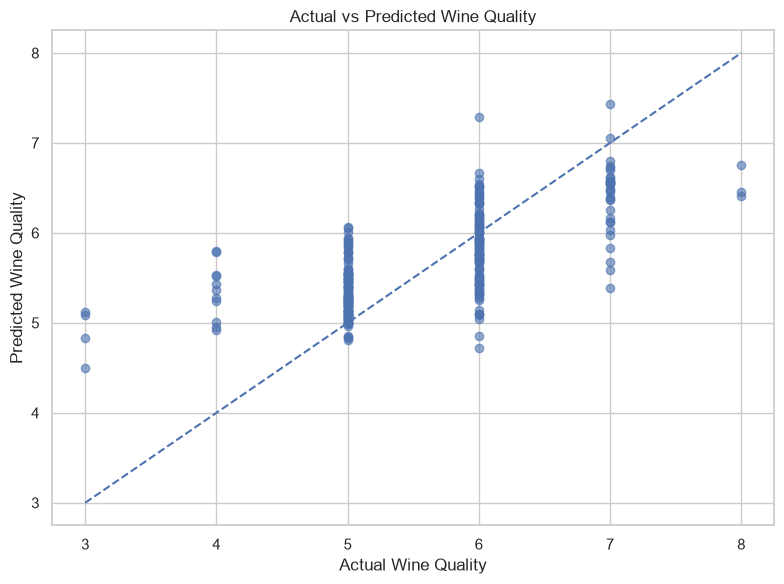

In [10]:
# Visualize actual and predicted wine quality

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

# Draw reference diagonal line

min_value = min(y_test.min(), y_pred.min())

max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Wine Quality")

plt.ylabel("Predicted Wine Quality")

plt.title("Actual vs Predicted Wine Quality")

plt.tight_layout()

plt.show()

In [11]:
# Extract feature importance from trained Random Forest

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
})

# Sort features by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Reset index

feature_importance.reset_index(
    drop=True,
    inplace=True
)

print("Feature Importance Results:")

display(feature_importance)

Feature Importance Results:


,Feature,Importance
0,alcohol,0.279930
1,sulphates,0.132840
2,volatile acidity,0.114777
3,total sulfur dioxide,0.079033
4,chlorides,0.067532
5,residual sugar,0.060038
6,pH,0.059178
7,density,0.055308
8,fixed acidity,0.052290
9,free sulfur dioxide,0.050751


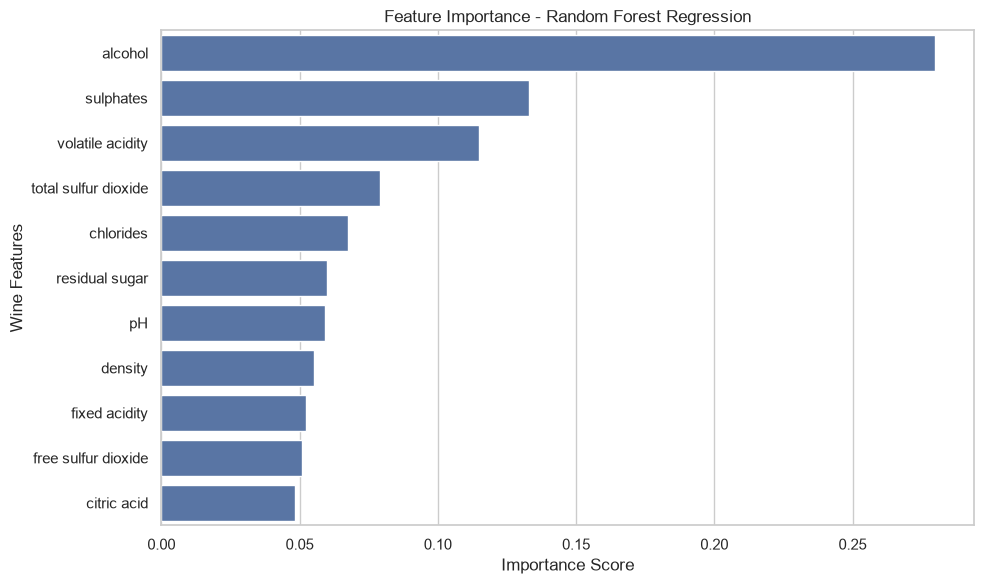

In [12]:
# Plot feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Feature Importance - Random Forest Regression"
)

plt.xlabel("Importance Score")

plt.ylabel("Wine Features")

plt.tight_layout()

plt.show()

In [13]:
# Create complete machine learning pipeline

final_model = Pipeline(
    steps=[
        ("preprocessing", preprocessing_pipeline),
        ("regressor", random_forest_model)
    ]
)

# Save trained model

MODEL_FILE = Path("wine_quality_random_forest.joblib")

joblib.dump(
    final_model,
    MODEL_FILE
)

print("Model Saved Successfully!")

print("Saved Model Location:")

print(MODEL_FILE.resolve())

Model Saved Successfully!
Saved Model Location:
C:\Users\pghat\Wine_Quality_Prediction\wine_quality_random_forest.joblib


In [14]:
# Load the saved model

loaded_model = joblib.load(
    MODEL_FILE
)

# Select one test sample

sample_input = X_test.iloc[[0]]

# Predict using the loaded model

sample_prediction = loaded_model.predict(
    sample_input
)

print("Saved Model Loaded Successfully!")

print(
    "Predicted Wine Quality:",
    round(float(sample_prediction[0]), 2)
)

print(
    "Actual Wine Quality:",
    y_test.iloc[0]
)

Saved Model Loaded Successfully!
Predicted Wine Quality: 5.0
Actual Wine Quality: 5


# Conclusion

In this project, a Wine Quality Prediction system was developed
using Random Forest Regression.

The UCI Red Wine Quality dataset was loaded and cleaned.
Missing feature values were handled using median imputation,
and feature scaling was performed using StandardScaler.

The dataset was divided into training and testing sets.
A Random Forest Regressor was trained using the training data.

The model was evaluated using:
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- R-squared Score

Feature importance was extracted and visualized to identify
the contribution of different physicochemical properties.

Finally, the trained preprocessing and regression pipeline
was saved using Joblib and successfully loaded for inference.

The project demonstrates how Machine Learning can be used
to predict wine quality based on its chemical properties.